<a href="https://colab.research.google.com/github/saichandanss2190/ITA0615-Machine-Learning-192312190-/blob/main/Exp_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Dataset Sample ===


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



=== Model Performance ===
Overall Accuracy: 91.11%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.79      1.00      0.88        15
   virginica       1.00      0.73      0.85        15

    accuracy                           0.91        45
   macro avg       0.93      0.91      0.91        45
weighted avg       0.93      0.91      0.91        45



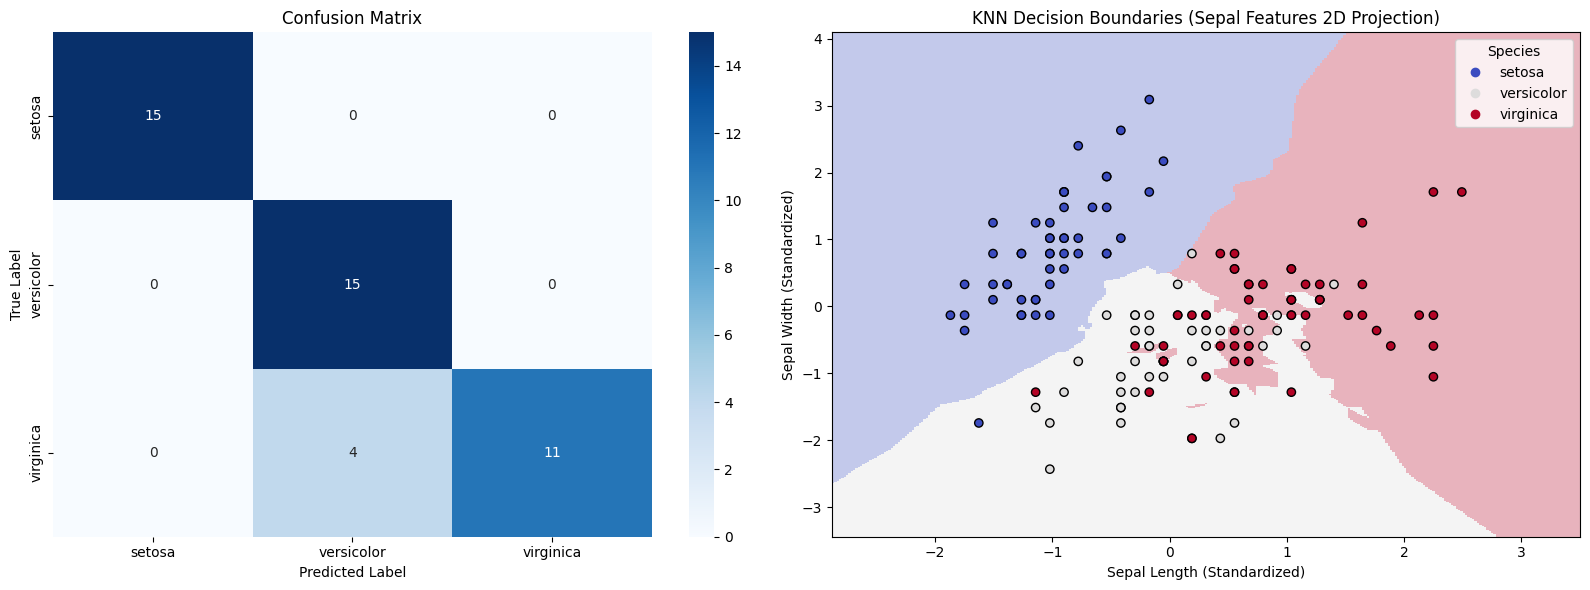

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

# Create a DataFrame for quick display
df = pd.DataFrame(X, columns=feature_names)
df['species'] = [target_names[i] for i in y]
print("=== Dataset Sample ===")
display(df.head())

# 2. Split dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# 3. Feature Scaling (Important for distance-based algorithms like KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Train the KNN Classifier (using k=5)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

# 5. Predict
y_pred = knn.predict(X_test_scaled)

# 6. Evaluate and present findings
accuracy = accuracy_score(y_test, y_pred)
print(f"\n=== Model Performance ===")
print(f"Overall Accuracy: {accuracy:.2%}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=target_names))

# 7. Visualizations (Confusion Matrix & Decision Boundaries)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names, ax=ax[0])
ax[0].set_title('Confusion Matrix')
ax[0].set_xlabel('Predicted Label')
ax[0].set_ylabel('True Label')

# Plot Decision Boundary (using 2D projection of first two features: Sepal Length & Sepal Width)
X_2d = X[:, :2]
scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(X_2d_scaled, y, test_size=0.3, random_state=42, stratify=y)

knn_2d = KNeighborsClassifier(n_neighbors=5)
knn_2d.fit(X_train_2d, y_train_2d)

h = .02  # step size in the mesh
x_min, x_max = X_2d_scaled[:, 0].min() - 1, X_2d_scaled[:, 0].max() + 1
y_min, y_max = X_2d_scaled[:, 1].min() - 1, X_2d_scaled[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
Z = knn_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

ax[1].pcolormesh(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.3, shading='auto')
scatter = ax[1].scatter(X_2d_scaled[:, 0], X_2d_scaled[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='k')
ax[1].set_title('KNN Decision Boundaries (Sepal Features 2D Projection)')
ax[1].set_xlabel('Sepal Length (Standardized)')
ax[1].set_ylabel('Sepal Width (Standardized)')
handles, _ = scatter.legend_elements()
ax[1].legend(handles, target_names, title="Species")

plt.tight_layout()
plt.show()